# 18 · Similarity search: vectors, maps, Zarr and SQL

**Time:** 40 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** calculate cosine similarity; test a reference and threshold; export a traceable geographic query.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=18_tessera_similarity.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Turn “looks similar” into a reproducible calculation

Choose one reference vector and compare all vectors to it. Cosine similarity is the dot product divided by the two vector lengths:

$$s(x,r)=\frac{x\cdot r}{\|x\|\|r\|}.$$

Scores range from −1 to 1. They are not probabilities. A score of 0.9 does not mean 90% confidence in a land-cover label.
Our reference is the native pixel selected by query row 32, column 32 in **2025**. The same vector is used for every year.
Its location is a demonstration choice with no supplied land-cover label.

Reference native pixel: 3.363226303908181 6.438798663111153
Reference self similarity: 1.0


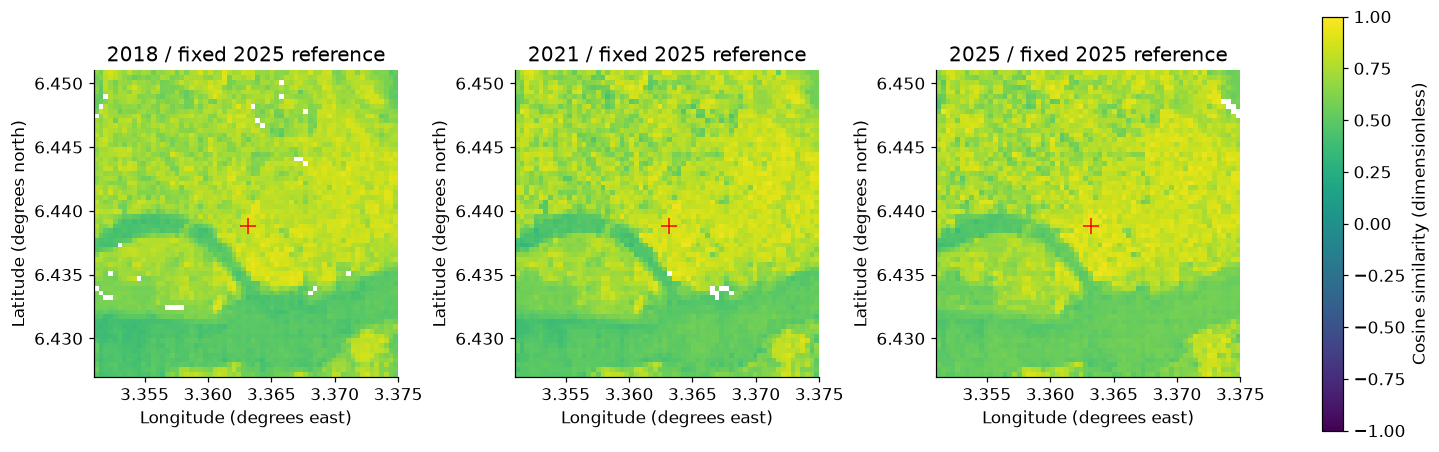

In [2]:
from tessera import load_tessera, unit_vectors, scalar_map, export_points
d=load_tessera('lagos')
U=unit_vectors(d['embedding'])
reference=U[-1,32,32]
similarity=np.clip(np.sum(U*reference,axis=-1),-1,1)
print('Reference native pixel:',d['native_lon'][32,32],d['native_lat'][32,32])
print('Reference self similarity:',similarity[-1,32,32])
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for i,ax in enumerate(axes):
    im=scalar_map(ax,d,similarity[i],f'{d["years"][i]} / fixed 2025 reference',cmap='viridis',vmin=-1,vmax=1)
    ax.plot(d['lon'][32],d['lat'][32],marker='+',color='red',ms=10)
fig.colorbar(im,ax=axes,label='Cosine similarity (dimensionless)')
plt.show()

## 2. A threshold is an analyst choice

The red cross marks the query reference. Similar pixels may have multiple explanations. Repeat the experiment with another
valid reference or threshold before describing a pattern. A self-match is a useful mathematical check, not a validation result.

The next chart measures the fraction of valid **sampled pixels**, not the fraction of the city's area or population.

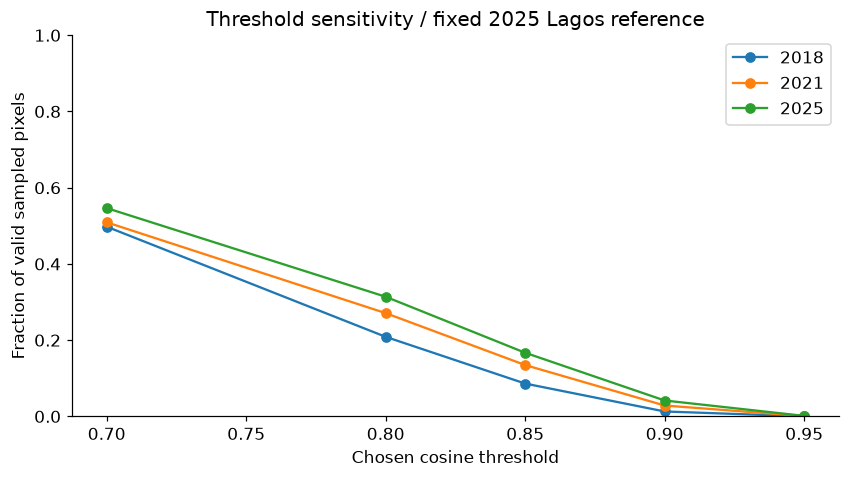

In [3]:
thresholds=np.array([.70,.80,.85,.90,.95])
fig,ax=plt.subplots()
for i,year in enumerate(d['years']):
    valid=np.isfinite(similarity[i])
    fractions=[np.count_nonzero(valid&(similarity[i]>=v))/valid.sum() for v in thresholds]
    ax.plot(thresholds,fractions,'o-',label=str(year))
ax.set(xlabel='Chosen cosine threshold',ylabel='Fraction of valid sampled pixels',ylim=(0,1),
       title='Threshold sensitivity / fixed 2025 Lagos reference')
ax.legend();plt.show()

## 3. Query the same scalar field with SQL

The original 128 dimensions stay in the notebook extracts. The linked lab stores the derived scalar similarity field
as a small uncompressed Zarr cube. Python uses SQLite; the lab uses DuckDB-WASM and Zarrita. SQL selects cells after the
metric is calculated: it does not invent a semantic label or train the foundation model.

In [4]:
meta,values=load_cube('tessera_lagos')
np.testing.assert_allclose(values,similarity,atol=1e-6,equal_nan=True)
con=sql_connection(meta,values)
rows=con.execute("""SELECT t, COUNT(*) AS selected, AVG(value) AS mean_similarity
 FROM cells WHERE value >= 0.85 GROUP BY t ORDER BY t""").fetchall()
print('Year index, selected count, selected mean:',rows)
con.close()
lab('tessera_lagos','cube')

Year index, selected count, selected mean: [(0, 350, 0.8764917308943613), (1, 550, 0.8812395452369343), (2, 682, 0.8839026611746231)]


Use the time slider, change the SQL predicate to `value >= 0.9`, and switch between 2D, columns and the time cube.
The time cube's layer spacing is an index of the three sampled years; it is not proportional to elapsed years.
Column height represents similarity, never terrain height or flood depth.

## 4. Carry the meaning with the exported points

This notebook exports actual native pixel centers and retains query coordinates, version, snapshot, reference and method.
The lab exports query-grid centers and explicitly describes its sampling in the dataset metadata.
Open the result in [GeoLibre](https://web.geolibre.app/) or another GeoJSON viewer that supports local file import.
Use a [STAC Browser](https://radiantearth.github.io/stac-browser/) with a suitable catalog to discover independent imagery.
Compare dates and provenance before interpreting a visual match.

In [5]:
result=export_points(d,similarity,'tessera-lagos-similarity.geojson',threshold=.9)
print('Exported',len(result['features']),'native-center points')
print('Reference:',result['method'])
print('A next-evidence question: do independently labeled surfaces explain these matches?')

Exported 338 native-center points
Reference: Cosine similarity to 2025 native pixel at query grid row=32, col=32; full 128 dimensions; normalized vectors.
A next-evidence question: do independently labeled surfaces explain these matches?


## Try it yourself

Try row 16, column 16 as the reference if valid; recalculate maps and threshold curves. Pass `reference=(2,16,16)` to the export helper so its metadata matches. The bundled lab retains its documented center reference; its equality check will correctly fail for your new derivative.

## Check your reasoning

High similarity supports retrieval within a chosen representation. A class label needs independent evidence. Changing the reference changes the selected set even when all calculations are correct.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [TESSERA project](https://geotessera.org/) and [model repository](https://github.com/ucam-eo/tessera), University of Cambridge and collaborators.
- [Feng et al., TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis](https://doi.org/10.48550/arXiv.2506.20380), 2025, revised 2026.
- [GeoTessera Python client](https://github.com/ucam-eo/geotessera), MIT; pinned preparation commit in the provenance.
- [dClimate global-store documentation](https://github.com/dClimate/tessera-embeddings/blob/main/docs/global-store.md): annual v1.1-dclimate embeddings and observation counts.
- [Bundled source snapshot, coordinates, transformations and checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/tessera-provenance.json). Embedding data: CC0-1.0; [upstream terms and advisory guidelines](https://github.com/ucam-eo/tessera/blob/master/aup.md).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 18_tessera_similarity')

LESSON COMPLETE: 18_tessera_similarity
